# <span style="color:green"> Laboratorio di Simulazione Numerica </span>
## <span style="color:blue"> Tommaso Cardano Chiezzi </span>


# Esercizio 06.1 — Modello di Ising 1D

In questo esercizio viene studiato il modello di Ising unidimensionale mediante simulazioni Monte Carlo.

Il sistema è costituito da $N=50$ spin

$$
s_i=\pm1,
$$

con condizioni periodiche al bordo,

$$
s_{N+1}=s_1,
$$

e Hamiltoniana

$$
H=-J\sum_{i=1}^{N}s_i s_{i+1}-h\sum_{i=1}^{N}s_i.
$$

Si utilizzano unità tali che

$$
J=1,\qquad k_B=1,
$$

per cui

$$
\beta=\frac{1}{T}.
$$

La distribuzione canonica viene campionata mediante due algoritmi Markov Chain Monte Carlo:

- algoritmo di **Metropolis**;
- algoritmo di **Gibbs** (heat-bath sampling).

Le proprietà termodinamiche vengono studiate nell'intervallo

$$
T\in[0.5,2.0],
$$

confrontando i risultati numerici dei due algoritmi con la soluzione analitica esatta del modello di Ising 1D.


## Struttura dell'analisi numerica

L'analisi viene organizzata in tre fasi.

### 1. Equilibrazione

Prima di effettuare le misure viene individuato un numero di Monte Carlo steps sufficientemente grande da permettere al sistema di perdere memoria della configurazione iniziale.

L'equilibrazione viene studiata a tre temperature rappresentative dell'intervallo considerato:

$$
T=0.5,\qquad T=1.0,\qquad T=2.0.
$$

Per ciascuna temperatura vengono confrontati:

- Metropolis e Gibbs;
- una configurazione iniziale **ordinata**, $s_i=+1$ per ogni spin;
- una configurazione iniziale **casuale**, con $s_i=\pm1$.

Una volta verificata l'equilibrazione, viene adottato un tempo di equilibrazione conservativo per tutte le simulazioni successive.

### 2. Proprietà termodinamiche a campo nullo

Per diverse temperature nell'intervallo $0.5\leq T\leq2.0$ vengono calcolate, a $h=0$,

$$
\frac{U}{N},\qquad \frac{C}{N},\qquad \frac{\chi}{N}.
$$

### 3. Magnetizzazione in campo esterno

Per $h=0.02$ viene calcolata la magnetizzazione per spin

$$
\frac{M}{N}=\frac{1}{N}\left\langle\sum_i s_i\right\rangle.
$$

In tutte le fasi vengono mantenuti in parallelo i risultati ottenuti con Metropolis e Gibbs.


## Algoritmi di campionamento

### Metropolis

Nel metodo di Metropolis viene selezionato uno spin $s_i$ e viene proposto il flip

$$
s_i\rightarrow-s_i.
$$

La variazione di energia associata alla mossa è

$$
\Delta E=2s_i\left[J(s_{i-1}+s_{i+1})+h\right].
$$

La mossa viene accettata con probabilità

$$
A=\min\left(1,e^{-\beta\Delta E}\right).
$$

### Gibbs sampling

Nel Gibbs sampling il nuovo valore dello spin viene estratto direttamente dalla distribuzione condizionata determinata dagli spin vicini.

Definendo il campo locale

$$
h_i^{\mathrm{loc}}=J(s_{i-1}+s_{i+1})+h,
$$

si ha

$$
P(s_i=+1)=\frac{1}{1+e^{-2\beta h_i^{\mathrm{loc}}}},
$$

$$
P(s_i=-1)=1-P(s_i=+1).
$$

Nel Gibbs sampling non è presente un passaggio di accept/reject: il nuovo valore dello spin viene campionato direttamente dalla distribuzione condizionata.

Per entrambi gli algoritmi un Monte Carlo step consiste in $N$ tentativi di aggiornamento degli spin.


## Equilibrazione e fase di produzione

Ogni simulazione viene separata in una fase di **equilibrazione** e in una successiva fase di **produzione**.

Durante l'equilibrazione le configurazioni generate non vengono utilizzate per il calcolo finale delle osservabili. Per lo studio preliminare vengono utilizzati

$$
N_{\mathrm{eq,blocks}}=2000
$$

intervalli da

$$
L_{\mathrm{eq}}=10
$$

Monte Carlo steps, per un totale di

$$
M_{\mathrm{eq}}=2\times10^4
$$

MC steps.

Durante questa fase vengono salvati:

1. l'energia per spin ad ogni MC step;
2. la media locale dell'energia su intervalli di $10$ MC steps.

La media progressiva non viene utilizzata per studiare il transiente, perché manterrebbe memoria dei valori iniziali fuori equilibrio.


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Vengono impostati alcuni parametri grafici comuni
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["font.size"] = 12


candidate_output_dirs = [
    Path("Esercizio_06.1") / "NSL_SIMULATOR" / "OUTPUT",
    Path("NSL_SIMULATOR") / "OUTPUT",
    Path("OUTPUT"),
    Path("..") / "Esercizio_06.1" / "NSL_SIMULATOR" / "OUTPUT"
]

output_dir = None

for candidate in candidate_output_dirs:
    if candidate.exists():
        output_dir = candidate
        break

if output_dir is None:
    raise FileNotFoundError(
        "La cartella OUTPUT del simulatore non è stata trovata."
    )


# ============================================================
# CARICAMENTO AUTOMATICO DEI DATI DI EQUILIBRAZIONE
# ============================================================

import re
import numpy as np

# Metodi, temperature e configurazioni considerate
methods = [
    "metropolis",
    "gibbs"
]

initial_states = [
    "ordered",
    "random"
]

T_eq = [
    0.5,
    1.0,
    2.0
]

# Etichette utilizzate nei grafici
method_labels = {
    "metropolis": "Metropolis",
    "gibbs": "Gibbs"
}

state_labels = {
    "ordered": "ordinata",
    "random": "casuale"
}


# Dizionario che conterrà tutti i dati caricati
equilibration = {}


# ============================================================
# 1. FILE CON I VALORI AD OGNI MC STEP
# ============================================================

energy_files = sorted(
    output_dir.glob(
        "equilibration_energy_*_T*_*.dat"
    )
)

for file in energy_files:

    # Viene estratta l'informazione direttamente dal nome del file
    match = re.match(
        r"equilibration_energy_(metropolis|gibbs)_"
        r"T(\d+)p(\d+)_(ordered|random)\.dat",
        file.name
    )

    if match is None:
        continue

    method = match.group(1)

    T = float(
        f"{match.group(2)}.{match.group(3)}"
    )

    initial_state = match.group(4)

    key = (
        method,
        T,
        initial_state
    )

    # Vengono caricati i dati numerici
    data = np.loadtxt(
        file,
        comments="#"
    )

    # Prima colonna: MC step
    equilibration.setdefault(
        key,
        {}
    )["step"] = data[:, 0]

    # Seconda colonna: energia per spin
    equilibration[
        key
    ]["energy"] = data[:, 1]


# ============================================================
# 2. FILE CON LE MEDIE LOCALI SU 10 MC STEPS
# ============================================================

block_files = sorted(
    output_dir.glob(
        "equilibration_blocks_*_T*_*.dat"
    )
)

for file in block_files:

    match = re.match(
        r"equilibration_blocks_(metropolis|gibbs)_"
        r"T(\d+)p(\d+)_(ordered|random)\.dat",
        file.name
    )

    if match is None:
        continue

    method = match.group(1)

    T = float(
        f"{match.group(2)}.{match.group(3)}"
    )

    initial_state = match.group(4)

    key = (
        method,
        T,
        initial_state
    )

    data = np.loadtxt(
        file,
        comments="#"
    )

    # Viene verificato che esista anche il corrispondente
    # file con i valori istantanei
    if key not in equilibration:
        equilibration[key] = {}

    # Prima colonna: indice del piccolo blocco
    equilibration[
        key
    ]["block"] = data[:, 0]

    # Seconda colonna: MC step corrispondente
    equilibration[
        key
    ]["block_step"] = data[:, 1]

    # Terza colonna: energia media nel piccolo blocco
    equilibration[
        key
    ]["block_energy"] = data[:, 2]


# ============================================================
# CONTROLLO FINALE
# ============================================================

print(
    f"Simulazioni di equilibrazione caricate: "
    f"{len(equilibration)}\n"
)

for key in sorted(
    equilibration.keys(),
    key=lambda x: (
        x[1],
        x[0],
        x[2]
    )
):

    method, T, initial_state = key

    print(
        f"{method_labels[method]:10s} | "
        f"T = {T:.1f} | "
        f"{state_labels[initial_state]}"
    )



files_eq = sorted(output_dir.glob("equilibration_*.dat"))




# Parametri del modello
N = 50
J = 1.0

# Intervallo di temperatura della simulazione finale
T_min = 0.5
T_max = 2.0

# Temperature utilizzate per lo studio dell'equilibrazione
T_eq = [0.5, 1.0, 2.0]

# Algoritmi utilizzati
methods = ["metropolis", "gibbs"]

# Configurazioni iniziali considerate
initial_states = ["ordered", "random"]

# Etichette utilizzate nei grafici
method_labels = {
    "metropolis": "Metropolis",
    "gibbs": "Gibbs"
}

state_labels = {
    "ordered": "ordinata",
    "random": "casuale"
}


Simulazioni di equilibrazione caricate: 12

Gibbs      | T = 0.5 | ordinata
Gibbs      | T = 0.5 | casuale
Metropolis | T = 0.5 | ordinata
Metropolis | T = 0.5 | casuale
Gibbs      | T = 1.0 | ordinata
Gibbs      | T = 1.0 | casuale
Metropolis | T = 1.0 | ordinata
Metropolis | T = 1.0 | casuale
Gibbs      | T = 2.0 | ordinata
Gibbs      | T = 2.0 | casuale
Metropolis | T = 2.0 | ordinata
Metropolis | T = 2.0 | casuale


## Soluzione esatta dell'energia

Durante lo studio dell'equilibrazione viene utilizzata l'energia interna per spin come osservabile di riferimento.

A campo magnetico nullo, definendo

$$
K=\frac{J}{T},\qquad t=\tanh K,
$$

l'energia interna esatta per spin di una catena finita con condizioni periodiche al bordo è

$$
\frac{U}{N}
=-J\frac{t+t^{N-1}}{1+t^N}.
$$

Il valore analitico permette di verificare sia la scomparsa del transiente sia la convergenza verso il corretto regime di equilibrio.


In [16]:
def exact_energy(T, N=50, J=1.0):
    """Calcola l'energia interna esatta per spin a campo nullo."""

    K = J / T
    t = np.tanh(K)

    return -J * (t + t**(N - 1)) / (1.0 + t**N)


# Vengono stampati i valori esatti alle temperature selezionate
for T in T_eq:
    u_exact = exact_energy(T, N, J)
    print(f"T = {T:.1f}   U/N = {u_exact:.8f}")


T = 0.5   U/N = -0.97414324
T = 1.0   U/N = -0.76159483
T = 2.0   U/N = -0.46211716


## Studio dell'equilibrazione

Prima di effettuare le misure delle osservabili termodinamiche è necessario lasciare evolvere la catena di Markov per un intervallo sufficientemente lungo da raggiungere il regime di equilibrio.

L'equilibrazione viene studiata seguendo l'evoluzione temporale dell'energia per spin,

$$
u(t)=\frac{U(t)}{N},
$$

in funzione del Monte Carlo time.

Per verificare che il risultato non dipenda dalla configurazione iniziale vengono considerate, come controllo diagnostico, due condizioni iniziali:

- configurazione **ordinata**, con
  $$
  s_i=+1 \qquad \forall i;
  $$
- configurazione **casuale**, con spin inizializzati indipendentemente a $\pm1$.

Il confronto viene effettuato sia con l'algoritmo di **Metropolis** sia con il **Gibbs sampling**, alle tre temperature rappresentative

$$
T=0.5,\qquad T=1.0,\qquad T=2.0.
$$

Per lo studio preliminare dell'equilibrazione vengono utilizzati

$$
N_{\mathrm{eq,blocks}}=2000
$$

intervalli da

$$
L_{\mathrm{eq}}=10
$$

Monte Carlo steps, per un totale di

$$
M_{\mathrm{eq}}
=
2000\times10
=
2\times10^4
$$

MC steps.

Durante questa fase l'energia viene salvata ad ogni singolo MC step, così da poter osservare direttamente il transiente iniziale. Vengono inoltre calcolate medie locali su intervalli di $10$ MC steps per rendere più leggibile l'andamento temporale.

Questi piccoli intervalli hanno solamente una funzione diagnostica e non costituiscono il data blocking utilizzato successivamente per stimare le osservabili e le relative incertezze statistiche.

### Transiente iniziale

Per individuare la scala temporale caratteristica del rilassamento vengono analizzati i primi Monte Carlo steps della simulazione.

I valori istantanei dell'energia vengono mostrati in trasparenza, mentre una breve media mobile viene sovrapposta per evidenziare l'andamento medio senza eliminare la struttura del transiente.

Le righe corrispondono alle due configurazioni iniziali, mentre le colonne rappresentano le tre temperature considerate.

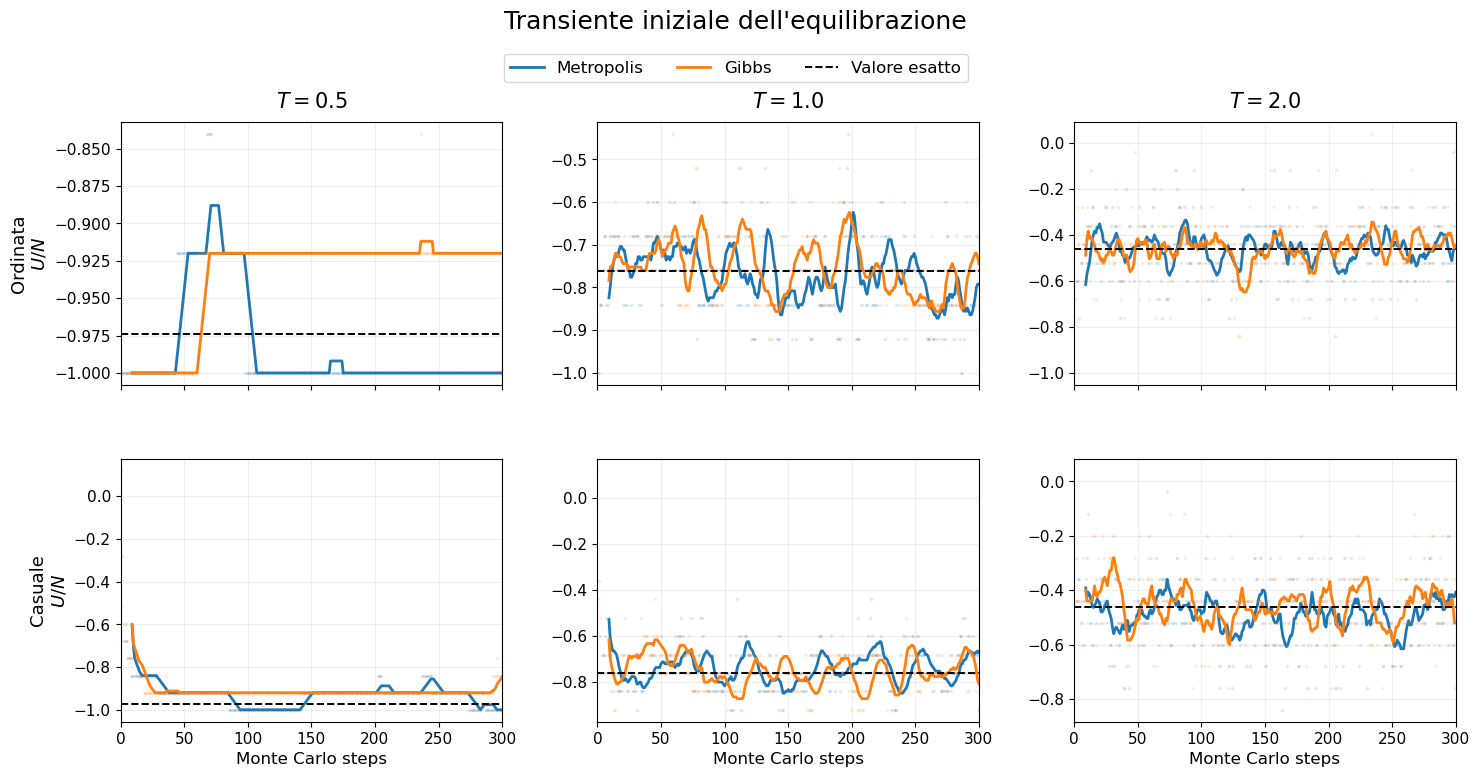

In [3]:
# ============================================================
# TRANSIENTE INIZIALE
# ============================================================
# ============================================================
# FUNZIONE PER LA MEDIA MOBILE
# ============================================================

def moving_average(x, window=10):
    """
    Calcola la media mobile su un numero fissato di punti.
    """

    x = np.asarray(x)

    kernel = np.ones(window) / window

    return np.convolve(
        x,
        kernel,
        mode="valid"
    )
# Intervallo temporale mostrato
max_step = 300

# Finestra utilizzata per evidenziare il rilassamento medio
window = 10

# Colori associati ai due algoritmi
colors = {
    "metropolis": "tab:blue",
    "gibbs": "tab:orange"
}

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 8),
    sharex=True
)

for row, initial_state in enumerate(
    ["ordered", "random"]
):

    for col, T in enumerate(T_eq):

        ax = axes[row, col]

        for method in methods:

            key = (
                method,
                T,
                initial_state
            )

            if key not in equilibration:
                continue

            data = equilibration[key]

            # Vengono selezionati solamente i primi MC steps
            mask = data["step"] <= max_step

            steps = data["step"][mask]
            energy = data["energy"][mask]

            # Vengono mostrate le fluttuazioni istantanee
            ax.plot(
                steps,
                energy,
                ".",
                color=colors[method],
                markersize=3,
                alpha=0.10
            )

            # Viene calcolata una breve media mobile
            energy_smooth = moving_average(
                energy,
                window
            )

            steps_smooth = steps[
                window - 1:
            ]

            ax.plot(
                steps_smooth,
                energy_smooth,
                color=colors[method],
                linewidth=2.0,
                label=method_labels[method]
            )

        # Valore analitico dell'energia
        ax.axhline(
            exact_energy(T, N, J),
            color="black",
            linestyle="--",
            linewidth=1.4,
            label="Valore esatto"
        )

        ax.set_xlim(
            0,
            max_step
        )

        ax.grid(
            alpha=0.20
        )

        ax.tick_params(
            axis="both",
            labelsize=11
        )

        # Titolo delle colonne
        if row == 0:

            ax.set_title(
                rf"$T={T:.1f}$",
                fontsize=15,
                pad=10
            )

        # Etichetta delle righe
        if col == 0:

            ax.set_ylabel(
                state_labels[initial_state].capitalize()
                + "\n"
                + r"$U/N$",
                fontsize=13
            )

        # Asse temporale solamente nell'ultima riga
        if row == 1:

            ax.set_xlabel(
                "Monte Carlo steps",
                fontsize=12
            )


fig.suptitle(
    "Transiente iniziale dell'equilibrazione",
    fontsize=18,
    y=0.98
)

# Viene costruita una sola legenda comune
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.935),
    ncol=3,
    fontsize=12,
    frameon=True
)

plt.subplots_adjust(
    left=0.09,
    right=0.98,
    bottom=0.09,
    top=0.84,
    wspace=0.25,
    hspace=0.28
)

plt.show()

### Osservazioni sul transiente

Il confronto mostra che la configurazione iniziale influenza principalmente i primi Monte Carlo steps della simulazione.

Alle temperature $T=1.0$ e $T=2.0$ sia Metropolis sia Gibbs perdono rapidamente memoria dello stato iniziale e raggiungono in poche decine di MC steps una regione compatibile con il valore teorico dell'energia.

A $T=0.5$ il rilassamento risulta più lento e l'energia presenta una maggiore persistenza temporale, come atteso in una regione in cui sono favorite configurazioni fortemente ordinate.

In tutti i casi il transiente osservato rimane comunque molto più breve dei

$$
2\times10^4
$$

MC steps complessivamente utilizzati per la fase di equilibrazione.

### Convergenza progressiva dell'energia

Oltre all'andamento locale viene analizzata anche la media progressiva dell'energia.

Per una sequenza di misure $u_k$,

$$
\overline{u}_n
=
\frac{1}{n}
\sum_{k=1}^{n}u_k.
$$

La media progressiva conserva memoria dell'intera storia della simulazione e non viene quindi utilizzata per individuare con precisione il tempo di rilassamento.

Essa costituisce tuttavia un utile controllo complementare, perché permette di verificare che Metropolis e Gibbs convergano verso lo stesso valore termodinamico e che l'effetto della configurazione iniziale diventi progressivamente trascurabile.

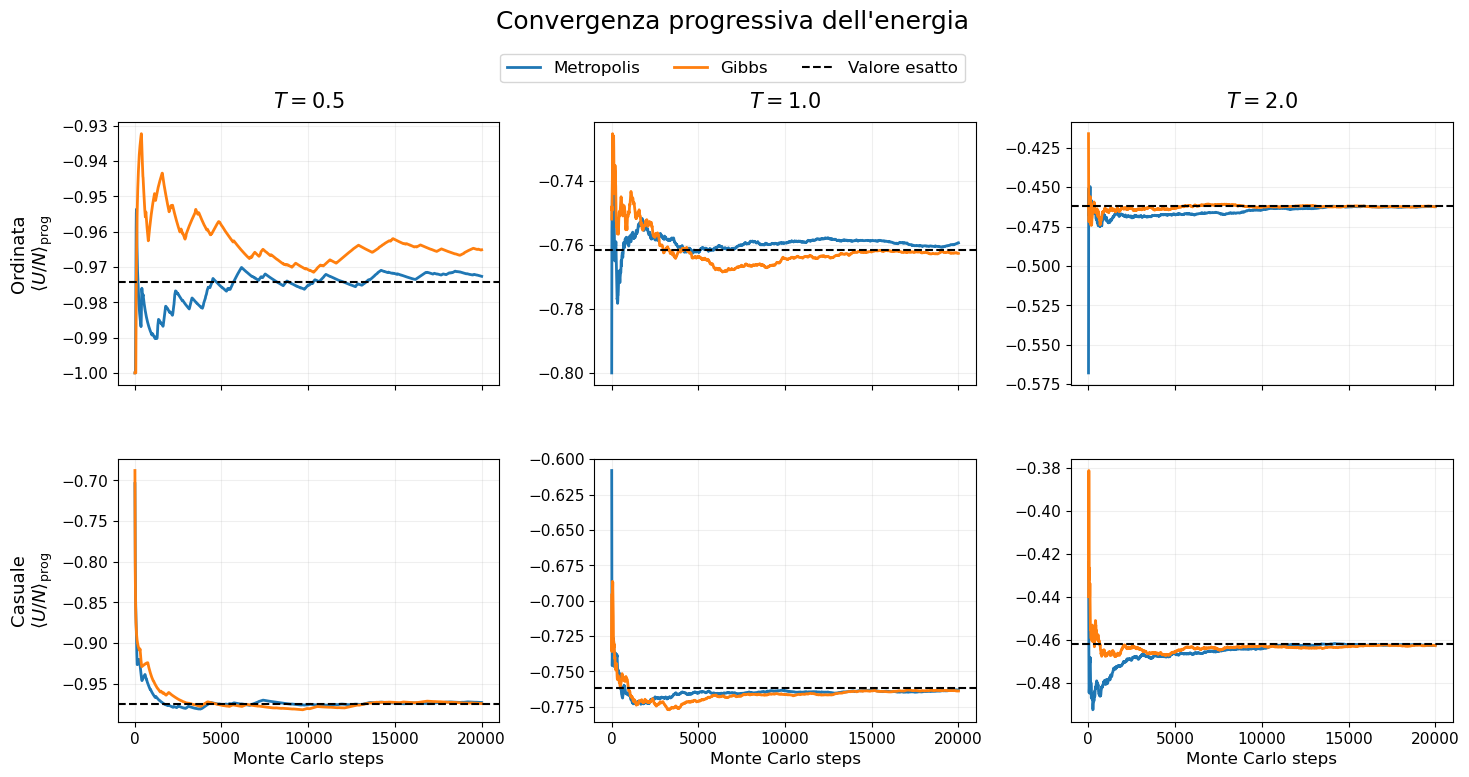

In [4]:
# ============================================================
# CONVERGENZA PROGRESSIVA DELL'ENERGIA
# ============================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 8),
    sharex="col"
)

for row, initial_state in enumerate(
    ["ordered", "random"]
):

    for col, T in enumerate(T_eq):

        ax = axes[row, col]

        for method in methods:

            key = (
                method,
                T,
                initial_state
            )

            if key not in equilibration:
                continue

            data = equilibration[key]

            # Vengono utilizzate le medie locali
            # calcolate ogni 10 MC steps
            steps = data["block_step"]
            energy = data["block_energy"]

            # Viene costruita la media progressiva
            progressive_energy = (
                np.cumsum(energy)
                / np.arange(1, len(energy) + 1)
            )

            ax.plot(
                steps,
                progressive_energy,
                color=colors[method],
                linewidth=2.0,
                label=method_labels[method]
            )

        # Valore analitico esatto
        ax.axhline(
            exact_energy(T, N, J),
            color="black",
            linestyle="--",
            linewidth=1.5,
            label="Valore esatto"
        )

        ax.grid(
            alpha=0.20
        )

        ax.tick_params(
            axis="both",
            labelsize=11
        )

        if row == 0:

            ax.set_title(
                rf"$T={T:.1f}$",
                fontsize=15,
                pad=10
            )

        if col == 0:

            ax.set_ylabel(
                state_labels[initial_state].capitalize()
                + "\n"
                + r"$\langle U/N\rangle_{\mathrm{prog}}$",
                fontsize=13
            )

        if row == 1:

            ax.set_xlabel(
                "Monte Carlo steps",
                fontsize=12
            )


fig.suptitle(
    "Convergenza progressiva dell'energia",
    fontsize=18,
    y=0.98
)

handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.935),
    ncol=3,
    fontsize=12,
    frameon=True
)

plt.subplots_adjust(
    left=0.09,
    right=0.98,
    bottom=0.09,
    top=0.84,
    wspace=0.25,
    hspace=0.28
)

plt.show()

### Verso la scelta del tempo di equilibrazione

Il confronto tra configurazioni iniziali ordinate e casuali mostra che, dopo il transiente iniziale, Metropolis e Gibbs evolvono verso lo stesso regime termodinamico.

L'utilizzo di due condizioni iniziali differenti costituisce quindi un controllo diagnostico della perdita di memoria dello stato iniziale. Nelle simulazioni successive viene adottata una configurazione iniziale **casuale**, evitando di privilegiare una particolare configurazione ordinata e mantenendo la stessa procedura di inizializzazione per tutte le temperature.

L'analisi dell'energia mostra inoltre che il rilassamento avviene su una scala temporale molto più breve dei

$$
2\times10^4
$$

MC steps utilizzati nella fase preliminare di equilibrazione.

Prima di fissare definitivamente questo valore come tempo di equilibrazione per la fase di produzione, viene effettuato un ulteriore controllo considerando anche le altre osservabili richieste nell'esercizio.

In particolare vengono analizzate, a partire dalla configurazione casuale,

$$
\frac{U}{N}, \qquad
\frac{C}{N}, \qquad
\frac{\chi}{N}, \qquad
\frac{M}{N}.
$$

Per energia, capacità termica e suscettibilità viene utilizzato campo nullo,

$$
h=0,
$$

mentre la magnetizzazione viene studiata nelle stesse condizioni previste per la misura finale,

$$
h=0.02.
$$

Poiché $C$ e $\chi$ sono determinate dalle fluttuazioni rispettivamente dell'energia e della magnetizzazione, la loro equilibrazione verrà osservata attraverso stime locali calcolate su intervalli finiti di Monte Carlo time, anziché mediante valori istantanei.

### Equilibrazione delle altre osservabili termodinamiche

Come ultimo controllo prima di fissare il tempo di equilibrazione viene analizzata la convergenza delle quattro osservabili richieste nell'esercizio.

Poiché il confronto precedente tra configurazione ordinata e casuale ha mostrato la progressiva perdita di memoria dello stato iniziale, da questo punto viene utilizzata una configurazione iniziale **casuale**. Questa scelta permette inoltre di partire da uno stato disordinato senza privilegiare una particolare configurazione ordinata.

Il controllo viene effettuato a

$$
T=0.5,
$$

che, tra le temperature analizzate, ha mostrato il rilassamento più lento.

Per energia, capacità termica e suscettibilità viene utilizzato campo nullo,

$$
h=0,
$$

mentre la magnetizzazione viene studiata a

$$
h=0.02,
$$

coerentemente con le condizioni previste per le misure finali.

Per rendere più evidente la convergenza vengono considerate le **stime progressive** delle osservabili.

Indicando con

$$
u_k=\frac{U_k}{N},
\qquad
m_k=\frac{M_k}{N},
$$

i valori misurati al $k$-esimo Monte Carlo step, l'energia progressiva viene calcolata come

$$
\overline{u}_n
=
\frac{1}{n}
\sum_{k=1}^{n}u_k.
$$

Per la capacità termica si utilizzano progressivamente il primo e il secondo momento dell'energia,

$$
\left(\frac{C}{N}\right)_n
=
\beta^2N
\left[
\overline{u^2}_n
-
\overline{u}_n^{\,2}
\right],
$$

mentre, a campo nullo, la suscettibilità viene stimata come

$$
\left(\frac{\chi}{N}\right)_n
=
\beta N\,\overline{m^2}_n.
$$

Infine, per $h=0.02$, la magnetizzazione viene rappresentata tramite

$$
\overline{m}_n
=
\frac{1}{n}
\sum_{k=1}^{n}m_k.
$$

La rappresentazione progressiva conserva memoria delle configurazioni precedenti e non viene quindi utilizzata per determinare con precisione il singolo istante in cui termina il transiente. Essa permette però di verificare in modo chiaro la stabilizzazione delle stime e di confrontare la convergenza di Metropolis e Gibbs.

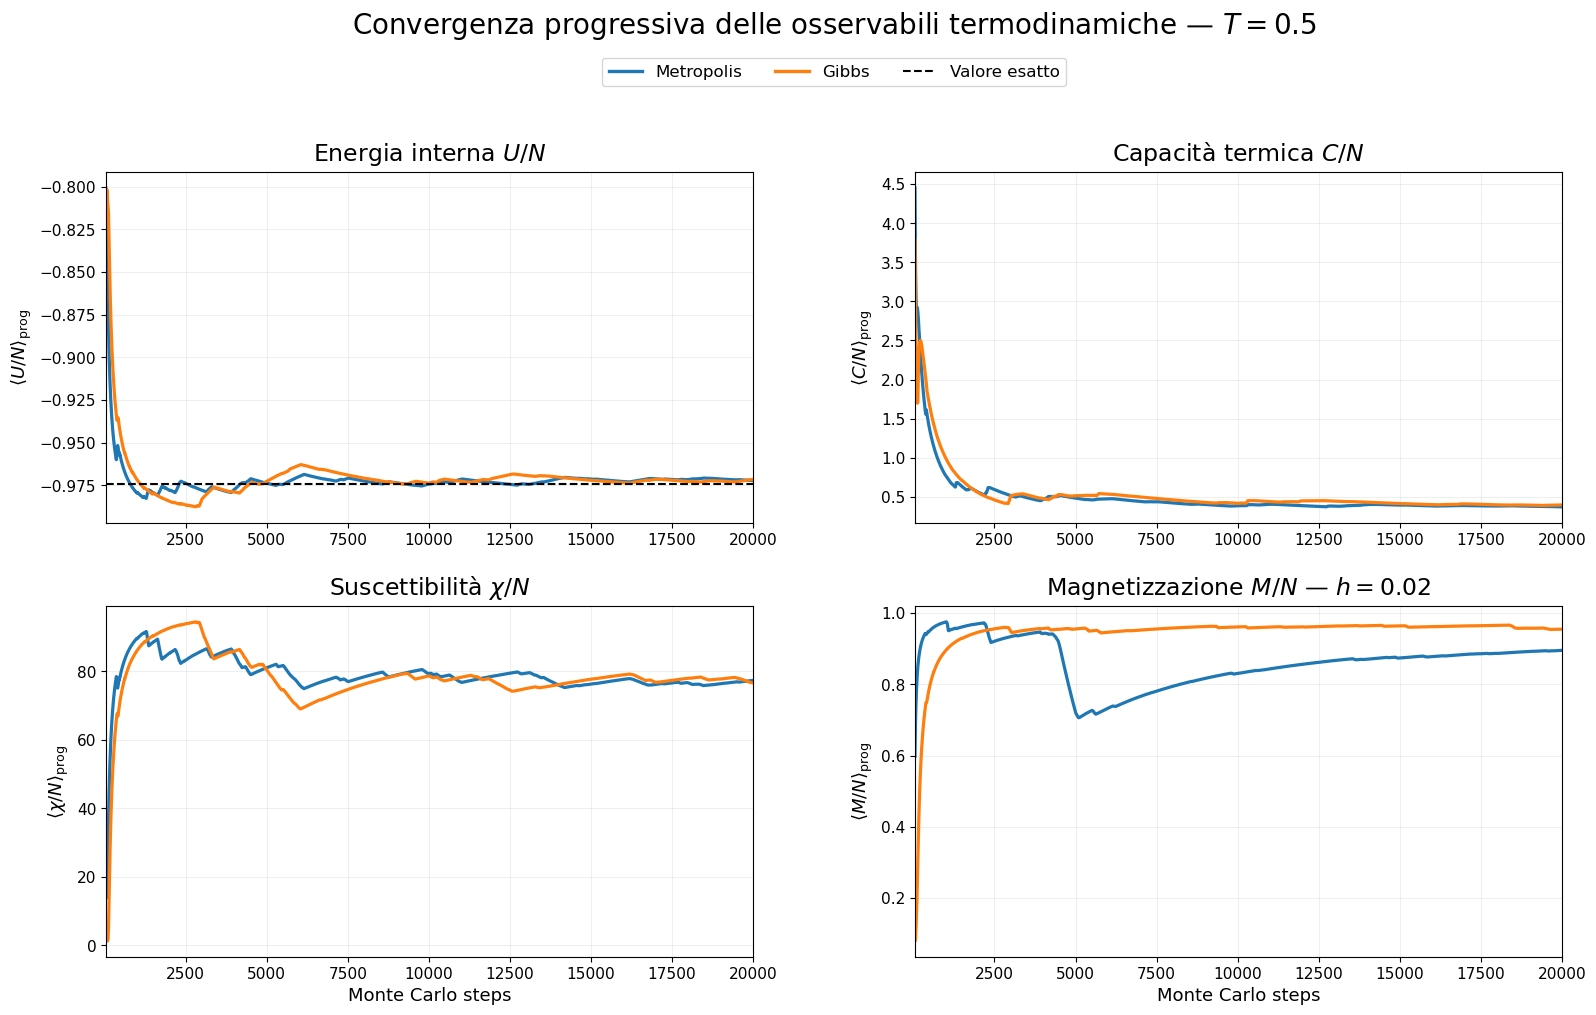

In [18]:
# ============================================================
# CARICAMENTO DEI DATI PER IL CONTROLLO DELLE OSSERVABILI
# ============================================================

observable_files = {
    
    ("metropolis", 0.00):
        output_dir / "equilibration_observables_metropolis_T0p5_h0.dat",

    ("gibbs", 0.00):
        output_dir / "equilibration_observables_gibbs_T0p5_h0.dat",

    ("metropolis", 0.02):
        output_dir / "equilibration_observables_metropolis_T0p5_h002.dat",

    ("gibbs", 0.02):
        output_dir / "equilibration_observables_gibbs_T0p5_h002.dat"
}


equilibration_observables = {}


for key, file in observable_files.items():

    if not file.exists():

        print(
            f"File non trovato: {file.name}"
        )

        continue


    data = np.loadtxt(
        file,
        comments="#"
    )

    equilibration_observables[key] = {
        "step": data[:, 0],
        "energy": data[:, 1],
        "magnetization": data[:, 2]
    }




# ============================================================
# CONVERGENZA PROGRESSIVA DELLE OSSERVABILI TERMODINAMICHE
# ============================================================

from matplotlib.lines import Line2D

T_focus = 0.5
beta = 1.0 / T_focus

# Le medie progressive vengono calcolate da t = 0,
# ma i primi step non vengono mostrati per migliorare la leggibilità
start_plot = 50

# Colori associati ai due algoritmi
colors = {
    "metropolis": "tab:blue",
    "gibbs": "tab:orange"
}


# ============================================================
# STRUTTURA DELLA FIGURA
# ============================================================

fig = plt.figure(
    figsize=(16, 10.5)
)

# La prima riga viene riservata a titolo e legenda
gs = fig.add_gridspec(
    3,
    2,
    height_ratios=[0.22, 1, 1],
    hspace=0.32,
    wspace=0.25
)

# Riga superiore
ax_header = fig.add_subplot(
    gs[0, :]
)

ax_header.axis("off")

# Quattro pannelli
ax_u   = fig.add_subplot(gs[1, 0])
ax_cv  = fig.add_subplot(gs[1, 1])
ax_chi = fig.add_subplot(gs[2, 0])
ax_m   = fig.add_subplot(gs[2, 1])


# ============================================================
# TITOLO GENERALE
# ============================================================

ax_header.text(
    0.5,
    0.82,
    r"Convergenza progressiva delle osservabili termodinamiche — $T=0.5$",
    ha="center",
    va="center",
    fontsize=20
)


# ============================================================
# LEGENDA COMUNE
# ============================================================

legend_handles = [
    
    Line2D(
        [0], [0],
        color=colors["metropolis"],
        linewidth=2.4,
        label="Metropolis"
    ),
    
    Line2D(
        [0], [0],
        color=colors["gibbs"],
        linewidth=2.4,
        label="Gibbs"
    ),
    
    Line2D(
        [0], [0],
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Valore esatto"
    )
]

ax_header.legend(
    handles=legend_handles,
    loc="center",
    bbox_to_anchor=(0.5, 0.22),
    ncol=3,
    fontsize=12,
    frameon=True
)


# ============================================================
# ENERGIA INTERNA U / N
# ============================================================

for method in methods:

    data = equilibration_observables[
        (method, 0.00)
    ]

    steps = data["step"]
    u = data["energy"]

    u_prog = (
        np.cumsum(u)
        / np.arange(1, len(u) + 1)
    )

    mask = steps >= start_plot

    ax_u.plot(
        steps[mask],
        u_prog[mask],
        color=colors[method],
        linewidth=2.3
    )


# Valore teorico
ax_u.axhline(
    exact_energy(T_focus, N, J),
    color="black",
    linestyle="--",
    linewidth=1.5
)

ax_u.set_title(
    r"Energia interna $U/N$",
    fontsize=17,
    pad=8
)

ax_u.set_ylabel(
    r"$\langle U/N\rangle_{\rm prog}$",
    fontsize=13
)

ax_u.grid(
    alpha=0.20
)


# ============================================================
# CAPACITÀ TERMICA C / N
# ============================================================

for method in methods:

    data = equilibration_observables[
        (method, 0.00)
    ]

    steps = data["step"]
    u = data["energy"]

    n = np.arange(
        1,
        len(u) + 1
    )

    mean_u_prog = (
        np.cumsum(u)
        / n
    )

    mean_u2_prog = (
        np.cumsum(u**2)
        / n
    )

    cv_prog = (
        beta**2
        * N
        * (
            mean_u2_prog
            - mean_u_prog**2
        )
    )

    mask = steps >= start_plot

    ax_cv.plot(
        steps[mask],
        cv_prog[mask],
        color=colors[method],
        linewidth=2.3
    )

ax_cv.set_title(
    r"Capacità termica $C/N$",
    fontsize=17,
    pad=8
)

ax_cv.set_ylabel(
    r"$\langle C/N\rangle_{\rm prog}$",
    fontsize=13
)

ax_cv.grid(
    alpha=0.20
)


# ============================================================
# SUSCETTIBILITÀ χ / N
# ============================================================

for method in methods:

    data = equilibration_observables[
        (method, 0.00)
    ]

    steps = data["step"]
    m = data["magnetization"]

    n = np.arange(
        1,
        len(m) + 1
    )

    mean_m2_prog = (
        np.cumsum(m**2)
        / n
    )

    chi_prog = (
        beta
        * N
        * mean_m2_prog
    )

    mask = steps >= start_plot

    ax_chi.plot(
        steps[mask],
        chi_prog[mask],
        color=colors[method],
        linewidth=2.3
    )

ax_chi.set_title(
    r"Suscettibilità $\chi/N$",
    fontsize=17,
    pad=8
)

ax_chi.set_xlabel(
    "Monte Carlo steps",
    fontsize=13
)

ax_chi.set_ylabel(
    r"$\langle \chi/N\rangle_{\rm prog}$",
    fontsize=13
)

ax_chi.grid(
    alpha=0.20
)


# ============================================================
# MAGNETIZZAZIONE M / N — h = 0.02
# ============================================================

for method in methods:

    data = equilibration_observables[
        (method, 0.02)
    ]

    steps = data["step"]
    m = data["magnetization"]

    m_prog = (
        np.cumsum(m)
        / np.arange(1, len(m) + 1)
    )

    mask = steps >= start_plot

    ax_m.plot(
        steps[mask],
        m_prog[mask],
        color=colors[method],
        linewidth=2.3
    )

ax_m.set_title(
    r"Magnetizzazione $M/N$ — $h=0.02$",
    fontsize=17,
    pad=8
)

ax_m.set_xlabel(
    "Monte Carlo steps",
    fontsize=13
)

ax_m.set_ylabel(
    r"$\langle M/N\rangle_{\rm prog}$",
    fontsize=13
)

ax_m.grid(
    alpha=0.20
)


# ============================================================
# IMPOSTAZIONI COMUNI
# ============================================================

for ax in [
    ax_u,
    ax_cv,
    ax_chi,
    ax_m
]:

    ax.tick_params(
        axis="both",
        labelsize=11
    )

    ax.set_xlim(
        start_plot,
        20000
    )


# Margini esterni
fig.subplots_adjust(
    left=0.07,
    right=0.98,
    bottom=0.07,
    top=0.97
)

plt.show()

### Osservazioni sulla convergenza

Le stime progressive mostrano comportamenti differenti a seconda dell'osservabile considerata.

L'energia interna converge rapidamente: sia Metropolis sia Gibbs si stabilizzano attorno al valore analitico e, dopo il transiente iniziale, le due stime risultano praticamente sovrapposte.

Anche la capacità termica presenta forti variazioni solamente nella fase iniziale. Il picco osservato nei primi MC steps è dovuto al fatto che la stima della varianza viene inizialmente costruita utilizzando un numero molto ridotto di configurazioni. Aumentando il numero di campioni, entrambe le stime si stabilizzano progressivamente sullo stesso intervallo di valori.

La suscettibilità mostra una convergenza più lenta e maggiori oscillazioni, coerentemente con la sua dipendenza dalle fluttuazioni della magnetizzazione. Nonostante ciò, nella seconda parte della simulazione Metropolis e Gibbs tendono verso valori compatibili.

La magnetizzazione a $h=0.02$ costituisce il caso più delicato. La simulazione Metropolis presenta una forte escursione della magnetizzazione intorno a $5\times10^3$ MC steps, che continua a influenzare la media progressiva anche molto tempo dopo l'evento. La curva torna successivamente a crescere, ma a $2\times10^4$ MC steps permane ancora una differenza visibile rispetto alla stima ottenuta con Gibbs.

Questo comportamento evidenzia una caratteristica importante della media progressiva: una fluttuazione significativa avvenuta nelle prime fasi continua a contribuire a tutti i valori successivi. Per questo motivo la mancata sovrapposizione completa delle curve progressive della magnetizzazione non implica necessariamente la presenza di un drift nello stato istantaneo del sistema.

Nel complesso, energia, capacità termica e suscettibilità mostrano una chiara stabilizzazione entro l'intervallo considerato, mentre la magnetizzazione rappresenta l'osservabile con la convergenza progressiva più lenta e costituisce quindi il controllo più restrittivo per la scelta definitiva del tempo di equilibrazione.

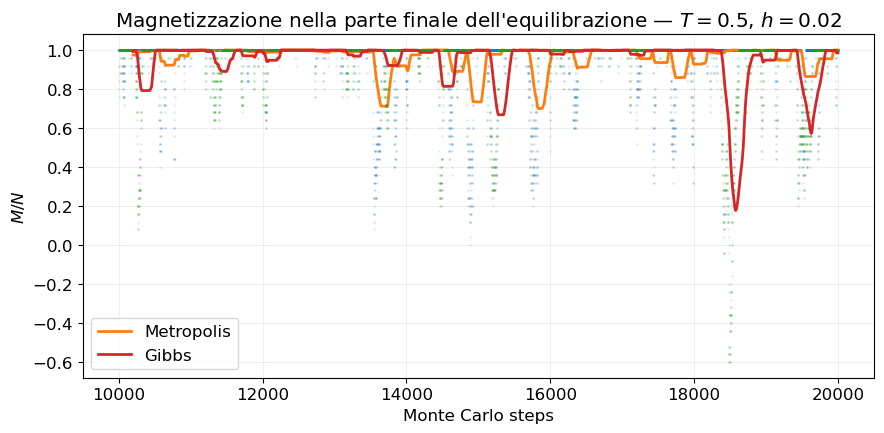

In [7]:
# ============================================================
# CONTROLLO FINALE DELLA MAGNETIZZAZIONE
# ============================================================

start_step = 10000
window = 200

fig, ax = plt.subplots(
    figsize=(9, 4.5)
)

for method in methods:

    data = equilibration_observables[
        (method, 0.02)
    ]

    steps = data["step"]
    magnetization = data["magnetization"]

    # Viene selezionata solamente la parte finale della simulazione
    mask = steps >= start_step

    steps_final = steps[mask]
    m_final = magnetization[mask]

    # Valori istantanei
    ax.plot(
        steps_final,
        m_final,
        ".",
        markersize=2,
        alpha=0.10
    )

    # Media mobile corta per evidenziare il comportamento locale
    m_smooth = moving_average(
        m_final,
        window
    )

    steps_smooth = steps_final[
        window - 1:
    ]

    ax.plot(
        steps_smooth,
        m_smooth,
        linewidth=2,
        label=method_labels[method]
    )

ax.set_xlabel(
    "Monte Carlo steps"
)

ax.set_ylabel(
    r"$M/N$"
)

ax.set_title(
    r"Magnetizzazione nella parte finale dell'equilibrazione — "
    r"$T=0.5$, $h=0.02$"
)

ax.grid(
    alpha=0.20
)

ax.legend()

plt.tight_layout()
plt.show()

### Scelta finale del tempo di equilibrazione

Il controllo della parte finale della traiettoria della magnetizzazione mostra che, dopo il transiente iniziale, sia Metropolis sia Gibbs evolvono in un regime statisticamente stazionario.

A $T=0.5$ e $h=0.02$ la magnetizzazione rimane prevalentemente prossima al valore positivo favorito dal campo esterno, pur presentando occasionali fluttuazioni anche di ampiezza significativa. Tali escursioni vengono successivamente riassorbite e non sono associate a un andamento sistematico crescente o decrescente.

La differenza osservata precedentemente tra le medie progressive di Metropolis e Gibbs è quindi principalmente dovuta alla memoria delle configurazioni visitate nelle prime fasi della simulazione, caratteristica intrinseca della media progressiva.

Considerando congiuntamente:

- il rilassamento dell'energia alle diverse temperature;
- la perdita di memoria della configurazione iniziale;
- la convergenza progressiva delle osservabili termodinamiche;
- il controllo locale della magnetizzazione nel caso più delicato;

viene adottato per tutte le simulazioni un tempo di equilibrazione conservativo pari a

$$
\boxed{
N_{\mathrm{eq}} = 2\times10^4
\ \text{MC steps}
}
$$

I primi $2\times10^4$ Monte Carlo steps vengono quindi scartati e le misure utilizzate nel data blocking vengono effettuate solamente sulla configurazione già equilibrata.

## Simulazioni di produzione e data blocking

Una volta fissato il tempo di equilibrazione,

$$
N_{\mathrm{eq}} = 2\times10^4
$$

Monte Carlo steps, vengono effettuate le simulazioni utilizzate per la stima delle osservabili termodinamiche.

Per ogni temperatura nell'intervallo

$$
0.5 \leq T \leq 2.0
$$

vengono eseguite simulazioni con passo

$$
\Delta T = 0.1,
$$

utilizzando entrambi gli algoritmi:

- **Metropolis**;
- **Gibbs sampling**.

Per ciascuna simulazione vengono utilizzati

$$
N_{\mathrm{blocks}}=100
$$

blocchi da

$$
L=10^4
$$

Monte Carlo steps, per un totale di

$$
M
=
N_{\mathrm{blocks}}L
=
10^6
$$

MC steps di produzione.

Le osservabili considerate sono

$$
\frac{U}{N},
\qquad
\frac{C}{N},
\qquad
\frac{\chi}{N},
\qquad
\frac{M}{N}.
$$

Energia interna, capacità termica e suscettibilità vengono calcolate a campo nullo,

$$
h=0,
$$

mentre la magnetizzazione viene misurata a

$$
h=0.02.
$$

Per ogni blocco viene calcolata una stima dell'osservabile. Le medie dei blocchi vengono quindi utilizzate per ottenere la media progressiva e la corrispondente incertezza statistica,

$$
\sigma_{\langle A\rangle}
=
\sqrt{
\frac{
\langle A^2\rangle
-
\langle A\rangle^2
}{
N_{\mathrm{blocks}}-1
}
}.
$$

I risultati Monte Carlo ottenuti con Metropolis e Gibbs verranno infine confrontati con la soluzione analitica del modello di Ising unidimensionale.

In [9]:
# ============================================================
# CARICAMENTO DEI RISULTATI FINALI
# ============================================================

temperatures = np.round(
    np.arange(
        0.5,
        2.0 + 0.1,
        0.1
    ),
    1
)

methods = [
    "metropolis",
    "gibbs"
]

observables = {
    "energy": {
        "stem": "total_energy",
        "h_tag": "h0p000"
    },

    "heat_capacity": {
        "stem": "specific_heat",
        "h_tag": "h0p000"
    },

    "susceptibility": {
        "stem": "susceptibility",
        "h_tag": "h0p000"
    },

    "magnetization": {
        "stem": "magnetization",
        "h_tag": "h0p020"
    }
}


production = {}


for observable, info in observables.items():

    for method in methods:

        for T in temperatures:

            # Viene costruita l'etichetta della temperatura
            T_tag = (
                f"T{T:.1f}"
                .replace(".", "p")
            )

            filename = (
                f"{info['stem']}_"
                f"{method}_"
                f"{T_tag}_"
                f"random_"
                f"{info['h_tag']}.dat"
            )

            file = (
                output_dir
                / filename
            )

            if not file.exists():

                print(
                    f"File non trovato: "
                    f"{filename}"
                )

                continue


            data = np.loadtxt(
                file,
                comments="#"
            )


            # L'ultima riga contiene:
            #
            # colonna 0 -> ultimo blocco
            # colonna 1 -> valore dell'ultimo blocco
            # colonna 2 -> media progressiva finale
            # colonna 3 -> errore finale

            production[
                (
                    observable,
                    method,
                    float(T)
                )
            ] = {
                "value": data[-1, 2],
                "error": data[-1, 3],
                "blocks": data[:, 0],
                "block_value": data[:, 1],
                "progressive": data[:, 2],
                "progressive_error": data[:, 3]
            }


print(
    f"\nRisultati caricati: "
    f"{len(production)}"
)

print(
    "Risultati attesi:",
    4 * 2 * len(temperatures)
)


Risultati caricati: 128
Risultati attesi: 128


## Confronto con la soluzione analitica

Il modello di Ising unidimensionale ammette una soluzione analitica esatta. I risultati ottenuti mediante Metropolis e Gibbs possono quindi essere confrontati direttamente con i valori teorici.

Per una catena di $N$ spin con condizioni periodiche, ponendo

$$
K=\beta J=\frac{J}{T},
\qquad
t=\tanh K,
$$

l'energia interna per spin a campo nullo è

$$
\frac{U}{N}
=
-J
\frac{
t+t^{N-1}
}{
1+t^N
}.
$$

La capacità termica viene ricavata dalla derivata dell'energia rispetto alla temperatura,

$$
\frac{C}{N}
=
\frac{\partial (U/N)}{\partial T}.
$$

A campo nullo, la suscettibilità per spin è

$$
\frac{\chi}{N}
=
\beta e^{2K}
\frac{
1-t^N
}{
1+t^N
}.
$$

Per la magnetizzazione a $h=0.02$ viene invece utilizzata la soluzione mediante matrice di trasferimento. Indicando con

$$
H=\beta h,
$$

gli autovalori della matrice di trasferimento sono

$$
\lambda_{\pm}
=
e^K\cosh H
\pm
\sqrt{
e^{2K}\sinh^2H+e^{-2K}
}.
$$

La funzione di partizione per la catena finita è

$$
Z_N
=
\lambda_+^N+\lambda_-^N,
$$

da cui viene calcolata la magnetizzazione per spin.

Le curve teoriche verranno confrontate con le stime Monte Carlo finali e con le relative incertezze statistiche ottenute mediante data blocking.

In [19]:
# ============================================================
# SOLUZIONI ANALITICHE DEL MODELLO DI ISING 1D
# ============================================================

def exact_energy(T, N=50, J=1.0):
    """
    Energia interna per spin a campo nullo.
    """

    K = J / T
    t = np.tanh(K)

    return -J * (
        t + t**(N - 1)
    ) / (
        1.0 + t**N
    )


def exact_heat_capacity(T, N=50, J=1.0):
    """
    Capacità termica per spin a campo nullo.

    Viene calcolata analiticamente la derivata
    dell'energia rispetto alla temperatura.
    """

    K = J / T
    t = np.tanh(K)

    # Numeratore e denominatore della funzione
    # che compare nell'energia per spin
    a = (
        t
        + t**(N - 1)
    )

    b = (
        1.0
        + t**N
    )

    # Derivate rispetto a t
    da_dt = (
        1.0
        + (N - 1) * t**(N - 2)
    )

    db_dt = (
        N * t**(N - 1)
    )

    df_dt = (
        da_dt * b
        - a * db_dt
    ) / b**2

    return (
        (J / T)**2
        * (1.0 - t**2)
        * df_dt
    )


def exact_susceptibility(T, N=50, J=1.0):
    """
    Suscettibilità per spin a campo nullo.
    """

    beta = 1.0 / T
    K = J / T
    t = np.tanh(K)

    return (
        beta
        * np.exp(2.0 * K)
        * (1.0 - t**N)
        / (1.0 + t**N)
    )


def exact_magnetization(T, h=0.02, N=50, J=1.0):
    """
    Magnetizzazione per spin a campo h != 0
    ottenuta mediante la matrice di trasferimento.
    """

    beta = 1.0 / T

    K = beta * J
    H = beta * h

    # Termine presente negli autovalori
    D = np.sqrt(
        np.exp(2.0 * K) * np.sinh(H)**2
        + np.exp(-2.0 * K)
    )

    # Autovalori della matrice di trasferimento
    lambda_plus = (
        np.exp(K) * np.cosh(H)
        + D
    )

    lambda_minus = (
        np.exp(K) * np.cosh(H)
        - D
    )

    # Derivata di D rispetto ad H
    dD_dH = (
        np.exp(2.0 * K)
        * np.sinh(H)
        * np.cosh(H)
        / D
    )

    # Derivate degli autovalori rispetto ad H
    dlambda_plus = (
        np.exp(K) * np.sinh(H)
        + dD_dH
    )

    dlambda_minus = (
        np.exp(K) * np.sinh(H)
        - dD_dH
    )

    # Magnetizzazione per spin
    numerator = (
        lambda_plus**(N - 1) * dlambda_plus
        + lambda_minus**(N - 1) * dlambda_minus
    )

    denominator = (
        lambda_plus**N
        + lambda_minus**N
    )

    return numerator / denominator

print("Controllo dei valori teorici a T = 1:\n")

print(
    f"U/N   = {exact_energy(1.0, N, J):.6f}"
)

print(
    f"C/N   = {exact_heat_capacity(1.0, N, J):.6f}"
)

print(
    f"χ/N   = {exact_susceptibility(1.0, N, J):.6f}"
)

print(
    f"M/N   = {exact_magnetization(1.0, 0.02, N, J):.6f}"
)

Controllo dei valori teorici a T = 1:

U/N   = -0.761595
C/N   = 0.419991
χ/N   = 7.389038
M/N   = 0.146203


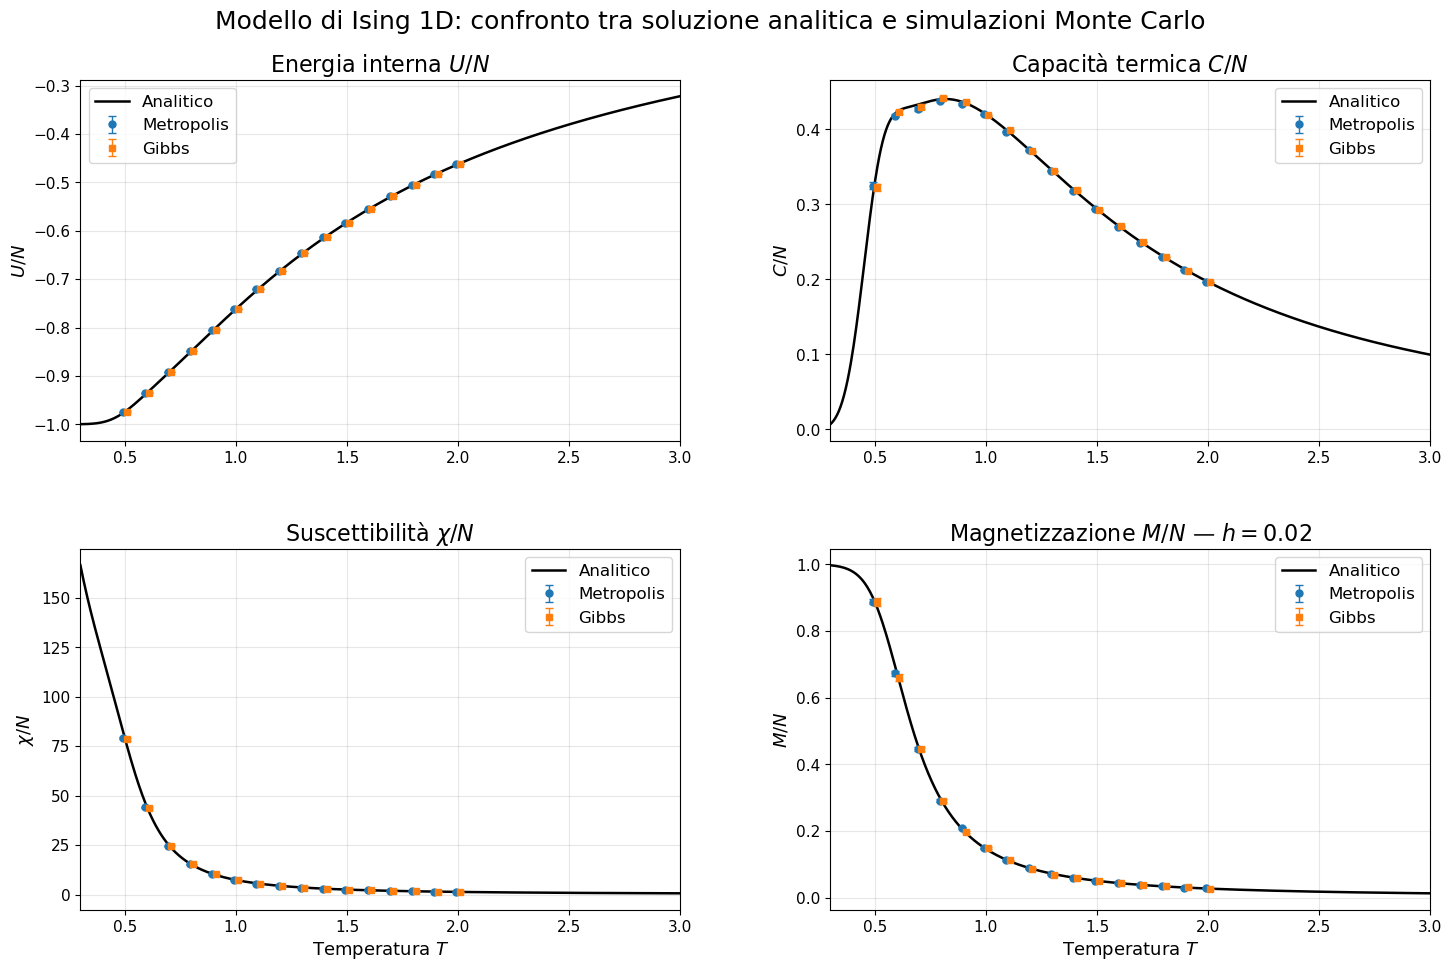

In [12]:
# ============================================================
# CONFRONTO FINALE:
# TEORIA - METROPOLIS - GIBBS
# ============================================================

# Griglia fitta utilizzata per le curve analitiche
# La teoria viene mostrata su un intervallo più ampio
# rispetto a quello simulato.
T_theory = np.linspace(
    0.3,
    3.0,
    700
)


# ============================================================
# CURVE TEORICHE
# ============================================================

U_theory = np.array([
    exact_energy(T, N, J)
    for T in T_theory
])

C_theory = np.array([
    exact_heat_capacity(T, N, J)
    for T in T_theory
])

chi_theory = np.array([
    exact_susceptibility(T, N, J)
    for T in T_theory
])

M_theory = np.array([
    exact_magnetization(
        T,
        h=0.02,
        N=N,
        J=J
    )
    for T in T_theory
])


# ============================================================
# FUNZIONE PER ESTRARRE I RISULTATI MONTE CARLO
# ============================================================

def get_mc_results(observable, method):

    values = []
    errors = []

    for T in temperatures:

        result = production[
            (
                observable,
                method,
                float(T)
            )
        ]

        values.append(
            result["value"]
        )

        errors.append(
            result["error"]
        )

    return (
        np.array(values),
        np.array(errors)
    )


# ============================================================
# DATI MONTE CARLO
# ============================================================

U_metro, U_metro_err = get_mc_results(
    "energy",
    "metropolis"
)

U_gibbs, U_gibbs_err = get_mc_results(
    "energy",
    "gibbs"
)


C_metro, C_metro_err = get_mc_results(
    "heat_capacity",
    "metropolis"
)

C_gibbs, C_gibbs_err = get_mc_results(
    "heat_capacity",
    "gibbs"
)


chi_metro, chi_metro_err = get_mc_results(
    "susceptibility",
    "metropolis"
)

chi_gibbs, chi_gibbs_err = get_mc_results(
    "susceptibility",
    "gibbs"
)


M_metro, M_metro_err = get_mc_results(
    "magnetization",
    "metropolis"
)

M_gibbs, M_gibbs_err = get_mc_results(
    "magnetization",
    "gibbs"
)


# ============================================================
# FIGURA
# ============================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(15, 10)
)

# Piccolo spostamento orizzontale per distinguere
# meglio le barre d'errore dei due algoritmi.
offset = 0.008

T_metro = temperatures - offset
T_gibbs = temperatures + offset


# ============================================================
# ENERGIA INTERNA U / N
# ============================================================

ax = axes[0, 0]

ax.plot(
    T_theory,
    U_theory,
    color="black",
    linewidth=1.8,
    label="Analitico"
)

ax.errorbar(
    T_metro,
    U_metro,
    yerr=U_metro_err,
    fmt="o",
    markersize=5,
    capsize=3,
    linewidth=1,
    label="Metropolis"
)

ax.errorbar(
    T_gibbs,
    U_gibbs,
    yerr=U_gibbs_err,
    fmt="s",
    markersize=5,
    capsize=3,
    linewidth=1,
    label="Gibbs"
)

ax.set_title(
    r"Energia interna $U/N$",
    fontsize=16
)

ax.set_ylabel(
    r"$U/N$",
    fontsize=13
)

ax.grid(
    alpha=0.30
)

ax.legend()


# ============================================================
# CAPACITÀ TERMICA C / N
# ============================================================

ax = axes[0, 1]

ax.plot(
    T_theory,
    C_theory,
    color="black",
    linewidth=1.8,
    label="Analitico"
)

ax.errorbar(
    T_metro,
    C_metro,
    yerr=C_metro_err,
    fmt="o",
    markersize=5,
    capsize=3,
    linewidth=1,
    label="Metropolis"
)

ax.errorbar(
    T_gibbs,
    C_gibbs,
    yerr=C_gibbs_err,
    fmt="s",
    markersize=5,
    capsize=3,
    linewidth=1,
    label="Gibbs"
)

ax.set_title(
    r"Capacità termica $C/N$",
    fontsize=16
)

ax.set_ylabel(
    r"$C/N$",
    fontsize=13
)

ax.grid(
    alpha=0.30
)

ax.legend()


# ============================================================
# SUSCETTIBILITÀ χ / N
# ============================================================

ax = axes[1, 0]

ax.plot(
    T_theory,
    chi_theory,
    color="black",
    linewidth=1.8,
    label="Analitico"
)

ax.errorbar(
    T_metro,
    chi_metro,
    yerr=chi_metro_err,
    fmt="o",
    markersize=5,
    capsize=3,
    linewidth=1,
    label="Metropolis"
)

ax.errorbar(
    T_gibbs,
    chi_gibbs,
    yerr=chi_gibbs_err,
    fmt="s",
    markersize=5,
    capsize=3,
    linewidth=1,
    label="Gibbs"
)

ax.set_title(
    r"Suscettibilità $\chi/N$",
    fontsize=16
)

ax.set_xlabel(
    r"Temperatura $T$",
    fontsize=13
)

ax.set_ylabel(
    r"$\chi/N$",
    fontsize=13
)

ax.grid(
    alpha=0.30
)

ax.legend()


# ============================================================
# MAGNETIZZAZIONE M / N
# ============================================================

ax = axes[1, 1]

ax.plot(
    T_theory,
    M_theory,
    color="black",
    linewidth=1.8,
    label="Analitico"
)

ax.errorbar(
    T_metro,
    M_metro,
    yerr=M_metro_err,
    fmt="o",
    markersize=5,
    capsize=3,
    linewidth=1,
    label="Metropolis"
)

ax.errorbar(
    T_gibbs,
    M_gibbs,
    yerr=M_gibbs_err,
    fmt="s",
    markersize=5,
    capsize=3,
    linewidth=1,
    label="Gibbs"
)

ax.set_title(
    r"Magnetizzazione $M/N$ — $h=0.02$",
    fontsize=16
)

ax.set_xlabel(
    r"Temperatura $T$",
    fontsize=13
)

ax.set_ylabel(
    r"$M/N$",
    fontsize=13
)

ax.grid(
    alpha=0.30
)

ax.legend()


# ============================================================
# IMPOSTAZIONI COMUNI
# ============================================================

for ax in axes.flat:

    ax.set_xlim(
        0.3,
        3.0
    )

    ax.set_xticks(
        np.arange(
            0.5,
            3.1,
            0.5
        )
    )

    ax.tick_params(
        axis="both",
        labelsize=11
    )


fig.suptitle(
    r"Modello di Ising 1D: confronto tra soluzione analitica e simulazioni Monte Carlo",
    fontsize=18,
    y=0.98
)

plt.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.08,
    top=0.91,
    wspace=0.25,
    hspace=0.30
)

plt.show()

### Confronto finale e conclusioni

Il confronto tra le simulazioni Monte Carlo e la soluzione analitica mostra un ottimo accordo per tutte le osservabili considerate.

Nell'intervallo simulato,

$$
0.5 \leq T \leq 2.0,
$$

i risultati ottenuti con **Metropolis** e **Gibbs sampling** risultano sostanzialmente sovrapposti e compatibili, entro le rispettive incertezze statistiche, con le curve teoriche.

L'energia interna per spin aumenta progressivamente con la temperatura, passando da valori prossimi allo stato fondamentale,

$$
\frac{U}{N}\simeq -1,
$$

a valori meno negativi all'aumentare di $T$.

La capacità termica presenta invece un massimo a temperatura intermedia, associato alla regione in cui le fluttuazioni dell'energia risultano maggiori. Anche in prossimità del massimo le due simulazioni riproducono correttamente l'andamento analitico.

La suscettibilità magnetica è molto elevata alle basse temperature e diminuisce rapidamente all'aumentare di $T$. Questo comportamento indica che, nella regione a bassa temperatura, il sistema risponde in maniera particolarmente intensa a una perturbazione magnetica esterna.

Infine, per

$$
h=0.02,
$$

la magnetizzazione è prossima alla completa polarizzazione alle temperature più basse e diminuisce progressivamente con l'aumentare della temperatura, seguendo anche in questo caso la previsione analitica.

Nel grafico le curve teoriche sono state estese all'intervallo

$$
0.3 \leq T \leq 3.0,
$$

mentre i punti Monte Carlo sono riportati esclusivamente nell'intervallo effettivamente simulato.

L'accordo tra i due algoritmi di campionamento e la soluzione esatta conferma sia la corretta implementazione di Metropolis e Gibbs sia l'adeguatezza della procedura di equilibrazione e del data blocking utilizzata per la stima delle osservabili e delle relative incertezze statistiche.

## Extra — Controllo del tempo di autocorrelazione

Come controllo aggiuntivo viene stimata l'autocorrelazione dell'energia nel caso più delicato analizzato,

$$
T=0.5,
\qquad
h=0.
$$

L'obiettivo è verificare che la lunghezza utilizzata per il data blocking,

$$
L=10^4
$$

Monte Carlo steps, sia molto maggiore della scala temporale caratteristica delle correlazioni presenti nella simulazione.

Per la serie temporale

$$
u(t)=\frac{U(t)}{N},
$$

si considera l'autocorrelazione normalizzata

$$
\rho(\tau)
=
\frac{
\langle u(t)u(t+\tau)\rangle-\langle u\rangle^2
}{
\langle u^2\rangle-\langle u\rangle^2
}.
$$

Il tempo di autocorrelazione integrato viene quindi stimato come

$$
\tau_{\mathrm{int}}
=
\frac{1}{2}
+
\sum_{\tau>0}\rho(\tau),
$$

interrompendo la somma quando l'autocorrelazione diventa non positiva.

Il confronto viene effettuato per entrambi gli algoritmi, Metropolis e Gibbs.

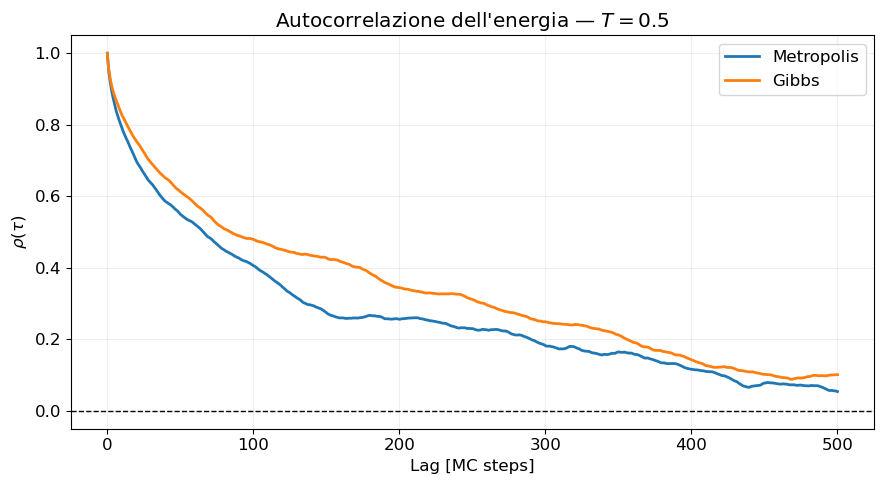

Tempo di autocorrelazione integrato:

Metropolis: tau_int = 134.73 MC steps
Gibbs     : tau_int = 167.24 MC steps

Lunghezza dei blocchi: L = 10000 MC steps


In [13]:
# ============================================================
# AUTOCORRELAZIONE DELL'ENERGIA A T = 0.5
# ============================================================

def autocorrelation(x, max_lag):

    x = np.asarray(x)
    x = x - np.mean(x)

    variance = np.mean(x**2)

    rho = np.empty(max_lag + 1)

    rho[0] = 1.0

    for lag in range(1, max_lag + 1):

        rho[lag] = np.mean(
            x[:-lag] * x[lag:]
        ) / variance

    return rho


def integrated_autocorrelation_time(rho):

    tau_int = 0.5

    for value in rho[1:]:

        # La somma viene arrestata quando
        # l'autocorrelazione diventa non positiva
        if value <= 0:
            break

        tau_int += value

    return tau_int


max_lag = 500
start_step = 5000

fig, ax = plt.subplots(
    figsize=(9, 5)
)

colors = {
    "metropolis": "tab:blue",
    "gibbs": "tab:orange"
}

tau_results = {}


for method in methods:

    data = equilibration_observables[
        (method, 0.00)
    ]

    steps = data["step"]
    energy = data["energy"]

    # Viene utilizzata solamente la parte già equilibrata
    mask = steps >= start_step

    energy_eq = energy[mask]

    rho = autocorrelation(
        energy_eq,
        max_lag
    )

    tau_int = integrated_autocorrelation_time(
        rho
    )

    tau_results[method] = tau_int

    ax.plot(
        np.arange(max_lag + 1),
        rho,
        linewidth=2,
        color=colors[method],
        label=method_labels[method]
    )


ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xlabel(
    "Lag [MC steps]"
)

ax.set_ylabel(
    r"$\rho(\tau)$"
)

ax.set_title(
    r"Autocorrelazione dell'energia — $T=0.5$"
)

ax.grid(alpha=0.20)

ax.legend()

plt.tight_layout()
plt.show()


print("Tempo di autocorrelazione integrato:\n")

for method in methods:

    print(
        f"{method_labels[method]:10s}: "
        f"tau_int = {tau_results[method]:.2f} MC steps"
    )

print(
    f"\nLunghezza dei blocchi: L = {10000} MC steps"
)

### Osservazioni

L'autocorrelazione dell'energia decresce progressivamente all'aumentare del lag, mostrando che configurazioni molto vicine nel Monte Carlo time risultano correlate, mentre tale dipendenza si riduce su scale temporali maggiori.

Nel caso considerato si ottiene

$$
\tau_{\mathrm{int}}^{\mathrm{Metropolis}}
\simeq 135
\ \text{MC steps},
$$

e

$$
\tau_{\mathrm{int}}^{\mathrm{Gibbs}}
\simeq 167
\ \text{MC steps}.
$$

Entrambi i valori risultano molto inferiori alla lunghezza utilizzata per ciascun blocco,

$$
L=10^4
\ \text{MC steps}.
$$

Si verifica quindi che

$$
L\gg\tau_{\mathrm{int}},
$$

confermando che la scelta della dimensione dei blocchi è ampiamente conservativa e che le medie ottenute da blocchi successivi possono essere considerate sostanzialmente indipendenti dal punto di vista statistico.

